# Laboratory Assignment 8: High-Performance Big Data Analytics Using R
**Dataset:** NYC TLC Yellow Taxi Trip Records  
**Environment:** Google Colab / Jupyter Notebook with an R kernel

## Problem statement
Analyze NYC Yellow Taxi Trip data and compare efficient R programming approaches: `data.table`, functional programming (`apply()`, `lapply()`, `purrr::map()`), vectorized operations, sequential and parallel processing (`foreach`, `doParallel`), benchmarking, and visualizations.


## 1. Install and load required packages

In [1]:
required_packages <- c(
  "data.table", "ggplot2", "foreach", "doParallel",
  "microbenchmark", "purrr", "lubridate", "arrow"
)
missing_packages <- required_packages[
  !vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(missing_packages)) {
  install.packages(missing_packages, repos = "https://cloud.r-project.org")
}
invisible(lapply(required_packages, library, character.only = TRUE))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘iterators’, ‘assertthat’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: iterators

Loading required package: parallel


Attaching package: ‘purrr’


The following objects are masked from ‘package:foreach’:

    accumulate, when


The following object is masked from ‘package:data.table’:

    transpose



Attaching package: ‘lubridate’


The following objects are masked from ‘package:data.table’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union



Attaching package: ‘arrow’


The following object is masked from ‘package:lubridate’:

    duration


The following object is masked from ‘package:utils’:

    timestamp




## 2. Configure and acquire the dataset

In [2]:
# NYC TLC publishes monthly Yellow Taxi files in Parquet format.
# Change these values to analyze another month/year.
TAXI_YEAR  <- 2024
TAXI_MONTH <- "01"   # "01" through "12"

taxi_url <- sprintf(
  "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_%d-%s.parquet",
  TAXI_YEAR, TAXI_MONTH
)
zones_url <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

dir.create("data", showWarnings = FALSE)
taxi_file <- file.path("data", sprintf("yellow_tripdata_%d-%s.parquet", TAXI_YEAR, TAXI_MONTH))
zones_file <- file.path("data", "taxi_zone_lookup.csv")

if (!file.exists(taxi_file)) {
  download.file(taxi_url, taxi_file, mode = "wb", quiet = FALSE)
}
if (!file.exists(zones_file)) {
  download.file(zones_url, zones_file, mode = "wb", quiet = FALSE)
}

cat("Taxi file:", taxi_file, "\n")
cat("Zone lookup:", zones_file, "\n")

Taxi file: data/yellow_tripdata_2024-01.parquet 
Zone lookup: data/taxi_zone_lookup.csv 


## 3. Read, inspect, and clean the data

In [3]:
trips <- as.data.table(arrow::read_parquet(taxi_file))
zones <- fread(zones_file)

cat("Rows:", nrow(trips), " Columns:", ncol(trips), "\n")
print(names(trips))
str(trips)
print(summary(trips))

# Standardize common TLC column names and keep relevant fields.
required_cols <- c(
  "tpep_pickup_datetime", "tpep_dropoff_datetime",
  "PULocationID", "DOLocationID", "passenger_count",
  "trip_distance", "fare_amount", "tip_amount",
  "tolls_amount", "total_amount", "payment_type"
)
missing_cols <- setdiff(required_cols, names(trips))
if (length(missing_cols)) {
  stop("Expected columns missing from the downloaded file: ",
       paste(missing_cols, collapse = ", "))
}

trips <- trips[, ..required_cols]
trips[, tpep_pickup_datetime := as.POSIXct(tpep_pickup_datetime, tz = "UTC")]
trips[, tpep_dropoff_datetime := as.POSIXct(tpep_dropoff_datetime, tz = "UTC")]

rows_before <- nrow(trips)
trips <- unique(trips)
trips <- trips[
  !is.na(tpep_pickup_datetime) &
  !is.na(tpep_dropoff_datetime) &
  tpep_dropoff_datetime >= tpep_pickup_datetime &
  !is.na(trip_distance) & trip_distance >= 0 &
  !is.na(fare_amount) & fare_amount >= 0 &
  !is.na(total_amount) & total_amount >= 0
]
cat("Rows before cleaning:", rows_before, "\n")
cat("Rows after cleaning:", nrow(trips), "\n")
cat("Rows removed:", rows_before - nrow(trips), "\n")

# Temporal features
trips[, `:=`(
  hour = lubridate::hour(tpep_pickup_datetime),
  day = lubridate::day(tpep_pickup_datetime),
  weekday = factor(
    lubridate::wday(tpep_pickup_datetime, label = TRUE, abbr = FALSE, week_start = 1),
    levels = c("Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday")
  ),
  month = lubridate::month(tpep_pickup_datetime, label = TRUE, abbr = TRUE),
  date = as.Date(tpep_pickup_datetime)
)]
print(trips[, .(rows = .N, mean_distance = mean(trip_distance),
                mean_fare = mean(fare_amount), total_revenue = sum(total_amount))])

Rows: 2964624  Columns: 19 
 [1] "VendorID"              "tpep_pickup_datetime"  "tpep_dropoff_datetime"
 [4] "passenger_count"       "trip_distance"         "RatecodeID"           
 [7] "store_and_fwd_flag"    "PULocationID"          "DOLocationID"         
[10] "payment_type"          "fare_amount"           "extra"                
[13] "mta_tax"               "tip_amount"            "tolls_amount"         
[16] "improvement_surcharge" "total_amount"          "congestion_surcharge" 
[19] "Airport_fee"          
Classes ‘data.table’ and 'data.frame':	2964624 obs. of  19 variables:
 $ VendorID             : int  2 1 1 1 1 1 2 1 2 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2024-01-01 00:57:55" "2024-01-01 00:03:00" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2024-01-01 01:17:43" "2024-01-01 00:09:36" ...
 $ passenger_count      : int  1 1 1 1 1 1 2 0 1 1 ...
 $ trip_distance        : num  1.72 1.8 4.7 1.4 0.8 ...
 $ RatecodeID           : int  1 1 1 1 1 1 1 1 1 1 ...
 $ store

## 4. Join pickup and drop-off zone information

In [4]:
zones <- as.data.table(zones)
setnames(zones, c("LocationID", "Borough", "Zone", "service_zone"),
         c("LocationID", "Borough", "Zone", "service_zone"), skip_absent = TRUE)

pickup_zones <- copy(zones)
setnames(pickup_zones,
         c("LocationID", "Borough", "Zone"),
         c("PULocationID", "pickup_borough", "pickup_zone"))

dropoff_zones <- copy(zones)
setnames(dropoff_zones,
         c("LocationID", "Borough", "Zone"),
         c("DOLocationID", "dropoff_borough", "dropoff_zone"))

trips <- merge(trips, pickup_zones[, .(PULocationID, pickup_borough, pickup_zone)],
               by = "PULocationID", all.x = TRUE)
trips <- merge(trips, dropoff_zones[, .(DOLocationID, dropoff_borough, dropoff_zone)],
               by = "DOLocationID", all.x = TRUE)

print(trips[1:5, .(pickup_zone, pickup_borough, dropoff_zone, dropoff_borough)])

      pickup_zone pickup_borough   dropoff_zone dropoff_borough
           <char>         <char>         <char>          <char>
1: Newark Airport            EWR Newark Airport             EWR
2: Newark Airport            EWR Newark Airport             EWR
3: Newark Airport            EWR Newark Airport             EWR
4: Newark Airport            EWR Newark Airport             EWR
5: Newark Airport            EWR Newark Airport             EWR


## 5. Transportation analytics using data.table

In [5]:
trips_by_hour <- trips[, .(trips = .N), by = hour][order(hour)]
trips_by_weekday <- trips[, .(trips = .N), by = weekday][order(weekday)]
trips_by_month <- trips[, .(trips = .N), by = month]
fare_revenue_by_date <- trips[, .(
  trips = .N,
  average_fare = mean(fare_amount, na.rm = TRUE),
  total_revenue = sum(total_amount, na.rm = TRUE)
), by = date][order(date)]

frequent_routes <- trips[, .(trips = .N),
  by = .(pickup_zone, dropoff_zone)][order(-trips)][1:10]
revenue_routes <- trips[, .(
  trips = .N, total_revenue = sum(total_amount, na.rm = TRUE)
), by = .(pickup_zone, dropoff_zone)][order(-total_revenue)][1:10]

distance_fare_summary <- trips[, .(
  correlation = cor(trip_distance, fare_amount, use = "complete.obs"),
  mean_distance = mean(trip_distance),
  mean_fare = mean(fare_amount)
)]

payment_summary <- trips[, .(
  trips = .N, revenue = sum(total_amount, na.rm = TRUE)
), by = .(pickup_borough, payment_type)][order(pickup_borough, -trips)]

top_pickups <- trips[, .(trips = .N), by = .(pickup_zone, pickup_borough)][order(-trips)][1:10]
top_dropoffs <- trips[, .(trips = .N), by = .(dropoff_zone, dropoff_borough)][order(-trips)][1:10]

cat("Trips by hour\n"); print(trips_by_hour)
cat("Trips by weekday\n"); print(trips_by_weekday)
cat("Monthly demand\n"); print(trips_by_month)
cat("Daily fare/revenue (first rows)\n"); print(head(fare_revenue_by_date))
cat("Most frequent routes\n"); print(frequent_routes)
cat("Highest revenue routes\n"); print(revenue_routes)
cat("Distance/fare summary\n"); print(distance_fare_summary)
cat("Payment methods by pickup borough\n"); print(payment_summary)
cat("Top pickup zones\n"); print(top_pickups)
cat("Top drop-off zones\n"); print(top_dropoffs)

Trips by hour
     hour  trips
    <int>  <int>
 1:     0  77687
 2:     1  52680
 3:     2  36779
 4:     3  24251
 5:     4  16301
 6:     5  18374
 7:     6  40872
 8:     7  82930
 9:     8 116118
10:     9 127728
11:    10 137282
12:    11 148882
13:    12 162541
14:    13 167873
15:    14 180807
16:    15 187055
17:    16 187873
18:    17 203813
19:    18 210098
20:    19 181704
21:    20 157911
22:    21 158763
23:    22 141175
24:    23 107503
     hour  trips
    <int>  <int>
Trips by weekday
     weekday  trips
       <ord>  <int>
1:    Monday 402790
2:   Tuesday 458002
3: Wednesday 489165
4:  Thursday 423512
5:    Friday 403411
6:  Saturday 415616
7:    Sunday 334504
Monthly demand
   month   trips
   <ord>   <int>
1:   Jan 2926986
2:   Dec      11
3:   Feb       3
Daily fare/revenue (first rows)
         date trips average_fare total_revenue
       <Date> <int>        <num>         <num>
1: 2002-12-31     1      6.50000         10.50
2: 2009-01-01     3     33.33333        

## 6. Functional programming vs vectorized vs data.table

In [6]:
# Equivalent task: count trips by pickup hour.
benchmark_input <- trips

base_vectorized <- function(x) {
  h <- lubridate::hour(x$tpep_pickup_datetime)
  as.data.frame(table(h), stringsAsFactors = FALSE)
}

apply_approach <- function(x) {
  # apply() is included for a repeated summary across numeric columns.
  numeric_cols <- x[, .(trip_distance, fare_amount, total_amount)]
  apply(numeric_cols, 2, function(z) c(mean = mean(z, na.rm = TRUE),
                                       sd = sd(z, na.rm = TRUE)))
}

lapply_approach <- function(x) {
  lapply(x[, .(trip_distance, fare_amount, total_amount)],
         function(z) c(mean = mean(z, na.rm = TRUE), sd = sd(z, na.rm = TRUE)))
}

purrr_map_approach <- function(x) {
  purrr::map(x[, .(trip_distance, fare_amount, total_amount)],
             ~ c(mean = mean(.x, na.rm = TRUE), sd = sd(.x, na.rm = TRUE)))
}

datatable_approach <- function(x) {
  x[, .(trips = .N), by = hour][order(hour)]
}

vectorized_approach <- function(x) {
  tab <- tabulate(x$hour + 1L, nbins = 24L)
  data.table(hour = 0:23, trips = tab)
}

# Confirm equivalent counts for vectorized and data.table implementations.
stopifnot(
  all(vectorized_approach(benchmark_input)$trips ==
      datatable_approach(benchmark_input)[match(0:23, hour), trips])
)

print(apply_approach(benchmark_input))
print(lapply_approach(benchmark_input))
print(purrr_map_approach(benchmark_input))
print(head(vectorized_approach(benchmark_input)))
print(head(datatable_approach(benchmark_input)))

     trip_distance fare_amount total_amount
mean       3.66046    18.65209     27.44880
sd       226.90628    18.34182     22.59479
$trip_distance
     mean        sd 
  3.66046 226.90628 

$fare_amount
    mean       sd 
18.65209 18.34182 

$total_amount
    mean       sd 
27.44880 22.59479 

$trip_distance
     mean        sd 
  3.66046 226.90628 

$fare_amount
    mean       sd 
18.65209 18.34182 

$total_amount
    mean       sd 
27.44880 22.59479 

    hour trips
   <int> <int>
1:     0 77687
2:     1 52680
3:     2 36779
4:     3 24251
5:     4 16301
6:     5 18374
    hour trips
   <int> <int>
1:     0 77687
2:     1 52680
3:     2 36779
4:     3 24251
5:     4 16301
6:     5 18374


## 7. Benchmark implementations

In [7]:
# Use a modest number of repetitions on large datasets to avoid excessive runtime.
# microbenchmark reports measured times for this machine and dataset.
bench <- microbenchmark::microbenchmark(
  vectorized = vectorized_approach(benchmark_input),
  data_table = datatable_approach(benchmark_input),
  times = 10L
)
print(bench)
benchmark_summary <- as.data.table(summary(bench))[
  , .(expression, min_ms = min / 1e6, median_ms = median / 1e6,
      mean_ms = mean / 1e6, max_ms = max / 1e6)
]
print(benchmark_summary)

# Compare base aggregation and data.table aggregation on the same hourly task.
base_hourly <- function(x) {
  h <- lubridate::hour(x$tpep_pickup_datetime)
  as.data.frame(table(h), stringsAsFactors = FALSE)
}
dt_hourly <- function(x) x[, .(trips = .N), by = hour][order(hour)]

bench_hourly <- microbenchmark::microbenchmark(
  base_R_table = base_hourly(benchmark_input),
  data_table = dt_hourly(benchmark_input),
  times = 10L
)
print(bench_hourly)

Unit: milliseconds
       expr      min       lq      mean   median       uq      max neval
 vectorized  7.27612  7.36356  7.514268  7.42831  7.59228  8.18402    10
 data_table 41.03409 41.53480 46.365609 42.57215 44.69725 68.52618    10
      expression       min_ms    median_ms      mean_ms       max_ms
          <list>        <num>        <num>        <num>        <num>
1: <function[1]> 7.276120e-06 7.428309e-06 7.514268e-06 8.184020e-06
2: <function[1]> 4.103409e-05 4.257215e-05 4.636561e-05 6.852618e-05
Unit: milliseconds
         expr       min        lq      mean    median       uq      max neval
 base_R_table 312.82719 322.81083 336.13142 335.73208 348.5365 358.6414    10
   data_table  40.98833  41.70881  50.94574  43.21312  45.3949 116.3418    10


## 8. Sequential vs parallel processing with foreach and doParallel

In [8]:
# Partition by day of month; each worker computes identical daily aggregates.
# On small datasets, parallel overhead may outweigh the benefit.
parts <- split(trips, trips$day)
parts <- parts[lengths(parts) > 0]

sequential_run <- function(partitions) {
  lapply(partitions, function(d) {
    d[, .(trips = .N, revenue = sum(total_amount, na.rm = TRUE)),
      by = day]
  })
}

seq_time <- system.time(seq_result <- sequential_run(parts))[["elapsed"]]

available_cores <- parallel::detectCores(logical = TRUE)
workers <- max(1L, min(4L, available_cores - 1L, length(parts)))
cl <- parallel::makeCluster(workers)
doParallel::registerDoParallel(cl)

parallel_time <- system.time({
  par_result <- foreach::foreach(
    i = seq_along(parts),
    .packages = "data.table",
    .combine = "rbind"
  ) %dopar% {
    d <- data.table::as.data.table(parts[[i]])
    d[, .(trips = .N, revenue = sum(total_amount, na.rm = TRUE)), by = day]
  }
})[["elapsed"]]

parallel::stopCluster(cl)
foreach::registerDoSEQ()

speedup <- if (parallel_time > 0) seq_time / parallel_time else NA_real_
parallel_comparison <- data.table(
  method = c("Sequential", "Parallel"),
  elapsed_seconds = c(seq_time, parallel_time),
  workers = c(1L, workers)
)
print(parallel_comparison)
cat("Speedup (sequential / parallel):", round(speedup, 3), "\n")

       method elapsed_seconds workers
       <char>           <num>   <int>
1: Sequential           0.088       1
2:   Parallel           4.557       1
Speedup (sequential / parallel): 0.019 


## 9. Visualizations using ggplot2

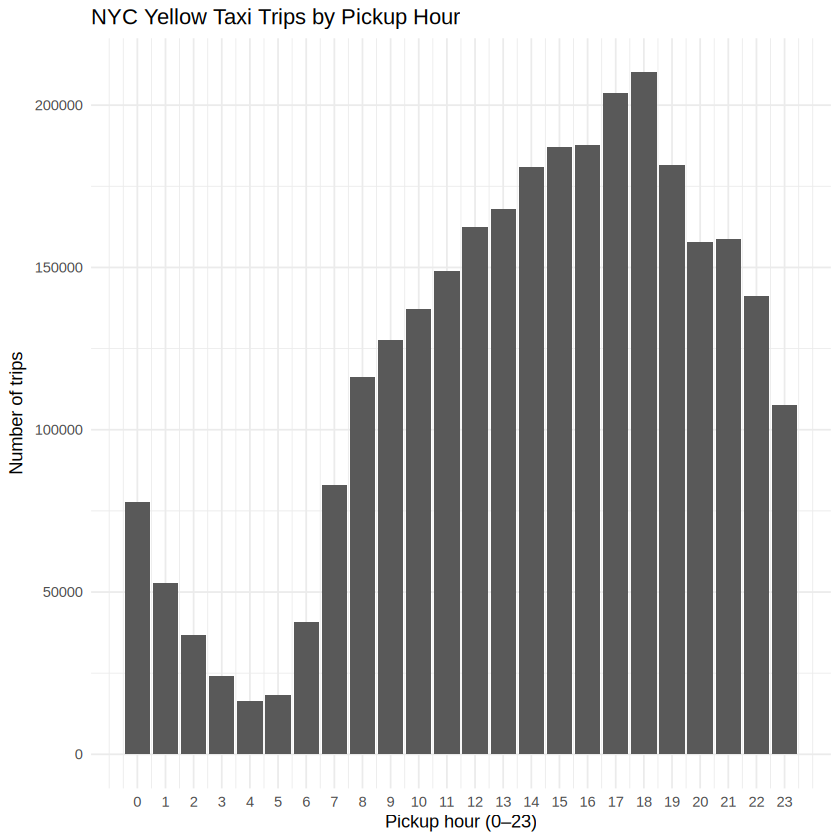

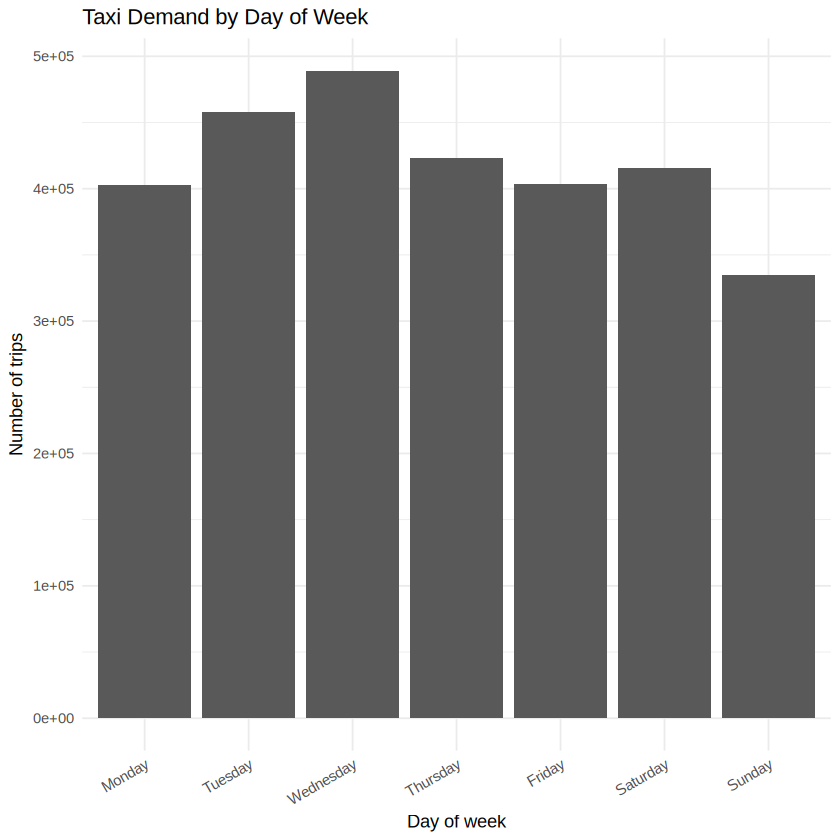

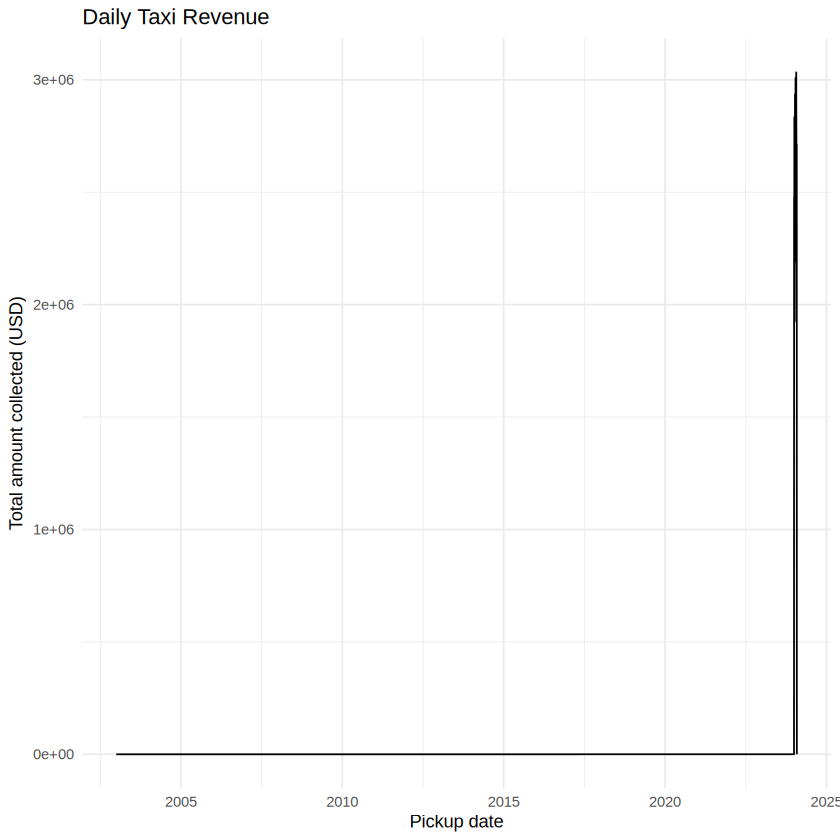

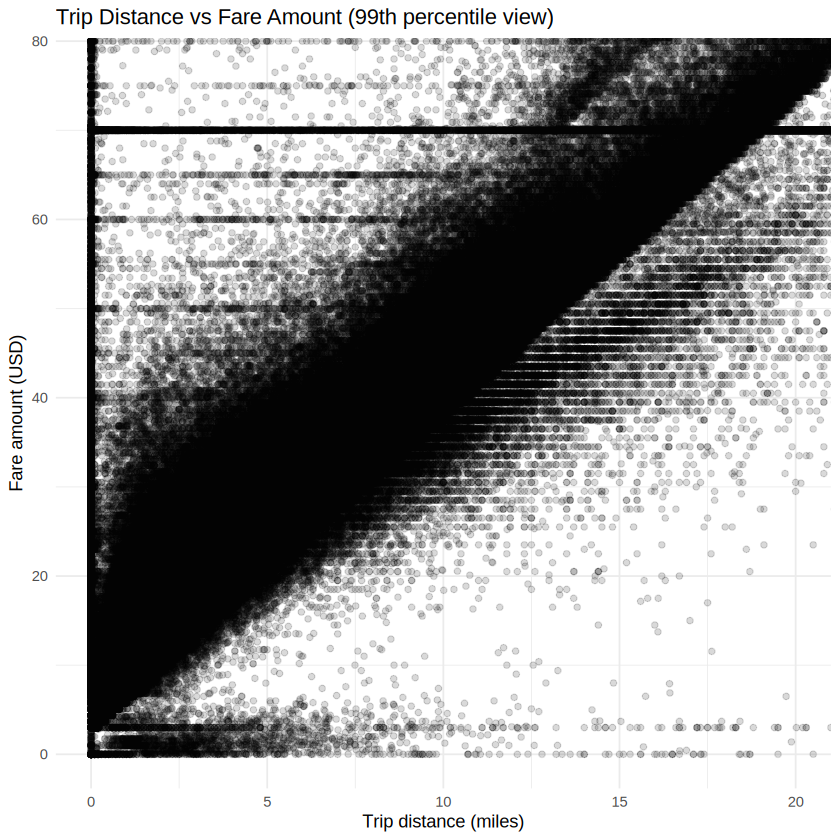

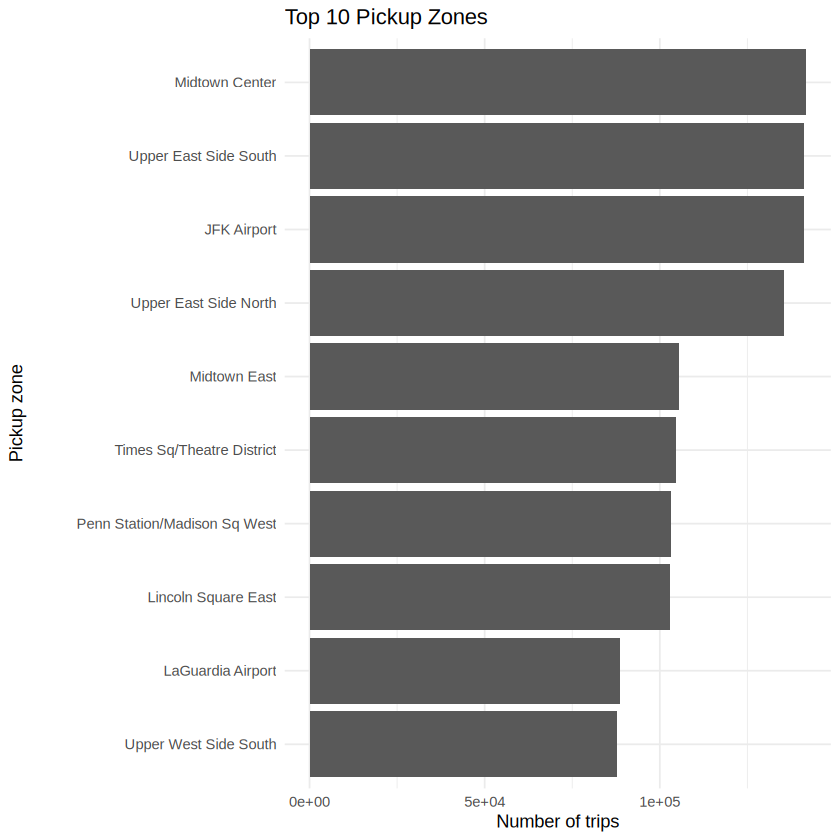

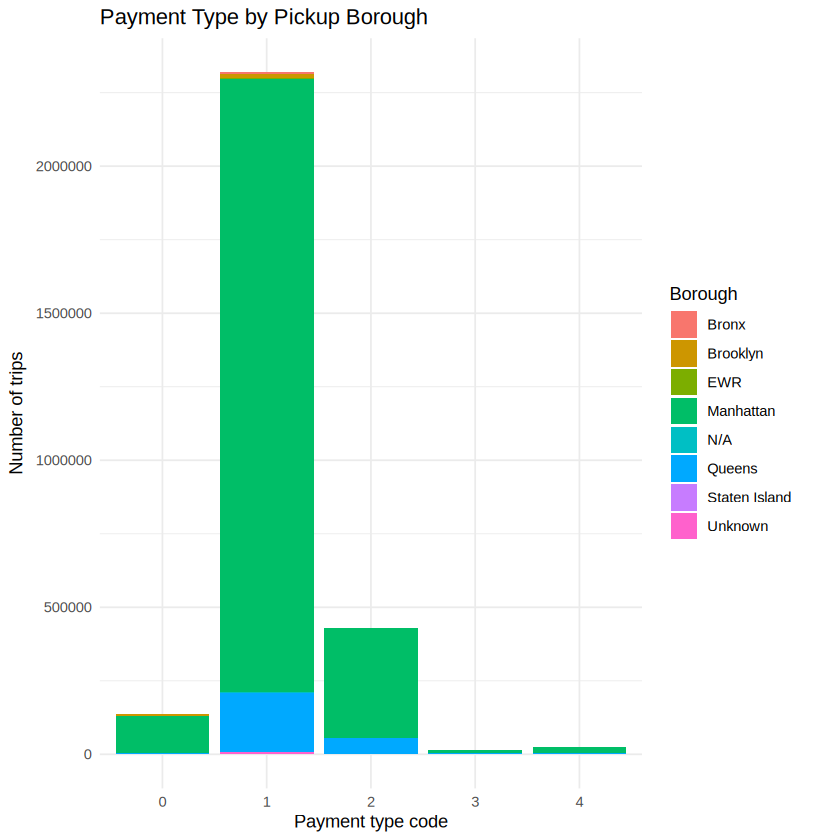

In [9]:
ggplot(trips_by_hour, aes(x = hour, y = trips)) +
  geom_col() +
  scale_x_continuous(breaks = 0:23) +
  labs(title = "NYC Yellow Taxi Trips by Pickup Hour",
       x = "Pickup hour (0–23)", y = "Number of trips") +
  theme_minimal()

ggplot(trips_by_weekday, aes(x = weekday, y = trips)) +
  geom_col() +
  labs(title = "Taxi Demand by Day of Week",
       x = "Day of week", y = "Number of trips") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

ggplot(fare_revenue_by_date, aes(x = date, y = total_revenue)) +
  geom_line() +
  labs(title = "Daily Taxi Revenue",
       x = "Pickup date", y = "Total amount collected (USD)") +
  theme_minimal()

ggplot(trips, aes(x = trip_distance, y = fare_amount)) +
  geom_point(alpha = 0.15) +
  coord_cartesian(xlim = quantile(trips$trip_distance, c(0, 0.99), na.rm = TRUE),
                  ylim = quantile(trips$fare_amount, c(0, 0.99), na.rm = TRUE)) +
  labs(title = "Trip Distance vs Fare Amount (99th percentile view)",
       x = "Trip distance (miles)", y = "Fare amount (USD)") +
  theme_minimal()

ggplot(top_pickups, aes(x = reorder(pickup_zone, trips), y = trips)) +
  geom_col() + coord_flip() +
  labs(title = "Top 10 Pickup Zones", x = "Pickup zone", y = "Number of trips") +
  theme_minimal()

ggplot(payment_summary, aes(x = factor(payment_type), y = trips, fill = pickup_borough)) +
  geom_col() +
  labs(title = "Payment Type by Pickup Borough",
       x = "Payment type code", y = "Number of trips", fill = "Borough") +
  theme_minimal()

## 10. Critical comparison template

In [10]:
# Generate a simple report table from the measured benchmark results.
# Fill in memory-use observations after monitoring your R session if required.
comparison <- data.table(
  approach = c("Base R table", "Vectorized tabulate", "data.table group-by",
               "lapply/apply/purrr", "Sequential partitions", "Parallel foreach"),
  execution_time = c(
    if (exists("bench_hourly")) paste(round(summary(bench_hourly)$median / 1e6, 3), "ms median (see rows)") else NA,
    if (exists("bench")) paste(round(summary(bench)$median / 1e6, 3), "ms median (see rows)") else NA,
    "See data_table benchmark",
    "Functional summaries executed; benchmark separately if needed",
    paste(round(seq_time, 3), "seconds"),
    paste(round(parallel_time, 3), "seconds")
  ),
  memory_efficiency = c("Often creates intermediate objects", "Low-overhead count operation",
                        "Efficient grouping; in-place updates possible",
                        "Depends on function and intermediate objects",
                        "Depends on partition copies", "Worker copies/serialization may increase memory"),
  scalability = c("Moderate", "High for simple numeric operations", "High",
                  "Useful for modular repeated operations", "Limited by one process",
                  "Useful for independent partitions, with overhead")
)
print(comparison)

Warning message in as.data.table.list(x, keep.rownames = keep.rownames, check.names = check.names, :
“Item 1 has 6 rows but longest item has 8; recycled with remainder.”
Warning message in as.data.table.list(x, keep.rownames = keep.rownames, check.names = check.names, :
“Item 3 has 6 rows but longest item has 8; recycled with remainder.”
Warning message in as.data.table.list(x, keep.rownames = keep.rownames, check.names = check.names, :
“Item 4 has 6 rows but longest item has 8; recycled with remainder.”


                approach
                  <char>
1:          Base R table
2:   Vectorized tabulate
3:   data.table group-by
4:    lapply/apply/purrr
5: Sequential partitions
6:      Parallel foreach
7:          Base R table
8:   Vectorized tabulate
                                                  execution_time
                                                          <char>
1:                                        0 ms median (see rows)
2:                                        0 ms median (see rows)
3:                                        0 ms median (see rows)
4:                                        0 ms median (see rows)
5:                                      See data_table benchmark
6: Functional summaries executed; benchmark separately if needed
7:                                                 0.088 seconds
8:                                                 4.557 seconds
                                 memory_efficiency
                                            <char